<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 04: Housing Price Prediction


The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [ ]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: U0j7JWGRuYWHOfiaSTLUq3qBHh756Ka7eX1krpmxoQV9bEwvTqLEm7TzfV5Oj6hztQ3GNgGNDOs=
x-amz-request-id: JS4VCY6NPCC84FV2
Server: AmazonS3
Date: Sat, 24 Oct 2026 17:31:54 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [ ]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Target is *Sales Price* and feature is *Lot Frontage*

Help investors evaluate whether lot frontage might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [ ]:
# Import the libraries and modules
from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

### Load Data

In [ ]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [ ]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [ ]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [ ]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [ ]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [ ]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [ ]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [ ]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [ ]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [ ]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

### Feature Nulls

In [ ]:
# Define the name of the feature columns to work with them independently (all floats are features)
feature_cols = df.select_dtypes(include=['int']).columns
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols]

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,905101070,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,0,7,2007
1,905101330,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,0,500,10,2006
2,903454090,50,9000,6,6,1937,1950,780,595,0,...,1,0,162,0,0,126,0,0,12,2007
3,533244030,60,7379,8,5,2000,2000,975,873,0,...,1,280,184,0,0,0,0,0,4,2010
4,909252020,70,7200,7,9,1936,2007,575,560,0,...,0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,6240,6,6,1934,1950,816,0,360,...,1,112,0,0,0,0,0,400,9,2006
2633,906201021,80,10778,7,6,1990,1991,1061,0,0,...,0,114,36,0,0,0,0,0,7,2009
2634,533253070,120,3782,8,5,1981,1981,1226,0,0,...,2,133,78,0,0,0,0,0,9,2009
2635,527376100,20,10140,6,5,1974,1974,1350,0,0,...,1,0,0,0,0,0,0,0,8,2009


In [ ]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
PID,0.0
MS SubClass,0.0
Lot Area,0.0
Overall Qual,0.0
Overall Cond,0.0
Year Built,0.0
Year Remod/Add,0.0
1st Flr SF,0.0
2nd Flr SF,0.0
Low Qual Fin SF,0.0


### Identifier Columns

In [ ]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [ ]:
# See proportion of unique values in the feature columns
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
1st Flr SF,38.756162
2nd Flr SF,22.335988
Wood Deck SF,13.917330
Open Porch SF,9.025408
Enclosed Porch,6.636329
Year Built,4.474782
Screen Porch,4.361016


In [ ]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes

,0
PID,int64
MS SubClass,int64
Lot Area,int64
Overall Qual,int64
Overall Cond,int64
Year Built,int64
Year Remod/Add,int64
1st Flr SF,int64
2nd Flr SF,int64
Low Qual Fin SF,int64


In [ ]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [ ]:
# Make a backup
df_bak1 = df.copy()

In [ ]:
# Restore from backup
df = df_bak1.copy()

### Working Data Frame

In [ ]:
# Define our target and feature columns as a data frame to work with 'iso_df'
iso_df = pd.concat([df[[target_col]], df[feature_cols]], axis=1).reset_index(drop=True)

In [ ]:
# Verify the working data frame
iso_df

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,905101070,20,14299,4,3,1964,1964,1005,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,905101330,90,10791,4,5,1967,1967,1296,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,903454090,50,9000,6,6,1937,1950,780,595,...,1,0,162,0,0,126,0,0,12,2007
3,254000,533244030,60,7379,8,5,2000,2000,975,873,...,1,280,184,0,0,0,0,0,4,2010
4,155000,909252020,70,7200,7,9,1936,2007,575,560,...,0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,903231070,50,6240,6,6,1934,1950,816,0,...,1,112,0,0,0,0,0,400,9,2006
2633,162000,906201021,80,10778,7,6,1990,1991,1061,0,...,0,114,36,0,0,0,0,0,7,2009
2634,211500,533253070,120,3782,8,5,1981,1981,1226,0,...,2,133,78,0,0,0,0,0,9,2009
2635,165000,527376100,20,10140,6,5,1974,1974,1350,0,...,1,0,0,0,0,0,0,0,8,2009


In [ ]:
iso_df.shape

(2637, 27)

### Backup #2

In [ ]:
# Make a backup
df_bak2 = df.copy()

In [ ]:
# Restore from backup
df = df_bak2.copy()

### Drop Identifier Column

In [ ]:
# Drop the identifier column 'PID'
id_col = 'PID'
iso_df_clean = iso_df.drop(columns=id_col)

In [ ]:
iso_df_clean

,SalePrice,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,50,9000,6,6,1937,1950,780,595,0,...,1,0,162,0,0,126,0,0,12,2007
3,254000,60,7379,8,5,2000,2000,975,873,0,...,1,280,184,0,0,0,0,0,4,2010
4,155000,70,7200,7,9,1936,2007,575,560,0,...,0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,50,6240,6,6,1934,1950,816,0,360,...,1,112,0,0,0,0,0,400,9,2006
2633,162000,80,10778,7,6,1990,1991,1061,0,0,...,0,114,36,0,0,0,0,0,7,2009
2634,211500,120,3782,8,5,1981,1981,1226,0,0,...,2,133,78,0,0,0,0,0,9,2009
2635,165000,20,10140,6,5,1974,1974,1350,0,0,...,1,0,0,0,0,0,0,0,8,2009


In [ ]:
# Verify rows dropped
iso_df_clean.shape

(2637, 26)

## EDA (Exploratory Data Analysis)

### Linear Regression Check

Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

#### Correlation with Target

In [ ]:
# Calculate a correlation matrix for the target
corr_mat = iso_df_clean.corr()
corr_mat

,SalePrice,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
SalePrice,1.000000,-0.078857,0.268516,0.805016,-0.095205,0.562777,0.539932,0.618247,0.268059,-0.040838,...,0.468886,0.322060,0.310361,-0.141685,0.040625,0.091214,0.072427,-0.019955,0.052800,-0.030053
MS SubClass,-0.078857,1.000000,-0.220406,0.046362,-0.069494,0.036241,0.042770,-0.249497,0.303093,0.016494,...,-0.037318,-0.016255,-0.011079,-0.027317,-0.035452,-0.048090,-0.005281,-0.016237,-0.006331,-0.015536
Lot Area,0.268516,-0.220406,1.000000,0.095071,-0.029723,0.030558,0.032820,0.347911,0.049998,-0.002348,...,0.257783,0.180943,0.118606,0.017355,0.022052,0.053741,0.101980,0.053556,0.015153,-0.027787
Overall Qual,0.805016,0.046362,0.095071,1.000000,-0.089281,0.595225,0.571035,0.467009,0.244258,-0.057611,...,0.390112,0.245627,0.295126,-0.153659,0.013418,0.028213,0.026957,-0.036647,0.042192,-0.020052
Overall Cond,-0.095205,-0.069494,-0.029723,-0.089281,1.000000,-0.359411,0.048439,-0.151234,0.002867,0.004491,...,-0.022691,0.030796,-0.068209,0.079232,0.045597,0.053407,-0.009012,0.030705,-0.009906,0.042123
Year Built,0.562777,0.036241,0.030558,0.595225,-0.359411,1.000000,0.614758,0.298960,0.022109,-0.139847,...,0.164347,0.220759,0.186176,-0.387146,0.013311,-0.056855,0.010353,-0.032083,0.014814,-0.014875
Year Remod/Add,0.539932,0.042770,0.032820,0.571035,0.048439,0.614758,1.000000,0.236601,0.159637,-0.062906,...,0.128849,0.210448,0.233864,-0.231342,0.033512,-0.054408,-0.014081,-0.034232,0.023667,0.035704
1st Flr SF,0.618247,-0.249497,0.347911,0.467009,-0.151234,0.298960,0.236601,1.000000,-0.261955,-0.018017,...,0.405815,0.208224,0.219278,-0.062983,0.057126,0.086365,0.138882,-0.008271,0.045737,-0.009183
2nd Flr SF,0.268059,0.303093,0.049998,0.244258,0.002867,0.022109,0.159637,-0.261955,1.000000,0.005746,...,0.161423,0.078973,0.199371,0.040455,-0.040098,0.026043,0.032547,0.018596,0.018123,-0.014703
Low Qual Fin SF,-0.040838,0.016494,-0.002348,-0.057611,0.004491,-0.139847,-0.062906,-0.018017,0.005746,1.000000,...,-0.007203,-0.006387,0.000429,0.081193,-0.010167,0.012985,-0.006026,-0.007538,0.009026,0.002094


##### Correlation Matrix

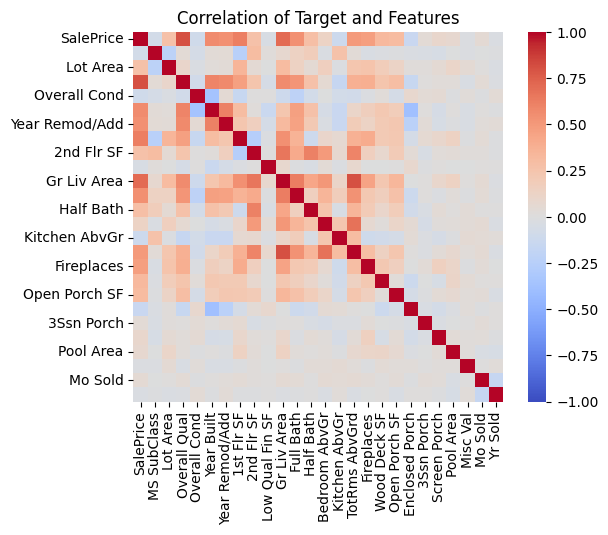

In [ ]:
# Display the correlation matrix - check if features correlated with the target
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation of Target and Features');

Couple features have low correlation with the target. Most have a high correlation of 0.5 or higher. Some of these features do have a high correlation with each other. They are not the best features to go with this target for our linear regression model.

##### Correlation Ranking

In [ ]:
corr_mat = iso_df_clean.corr().round(2).unstack().abs()
corr_mat.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,MS SubClass,0.08
2,SalePrice,Lot Area,0.27
3,SalePrice,Overall Qual,0.81
4,SalePrice,Overall Cond,0.10
...,...,...,...
671,Yr Sold,Screen Porch,0.01
672,Yr Sold,Pool Area,0.05
673,Yr Sold,Misc Val,0.03
674,Yr Sold,Mo Sold,0.16


In [ ]:
# Create a data series with features ranked by correlation
corr_mat = corr_mat[corr_mat < 1]
corr_mat.reset_index()

,level_0,level_1,0
0,SalePrice,MS SubClass,0.08
1,SalePrice,Lot Area,0.27
2,SalePrice,Overall Qual,0.81
3,SalePrice,Overall Cond,0.10
4,SalePrice,Year Built,0.56
...,...,...,...
645,Yr Sold,3Ssn Porch,0.01
646,Yr Sold,Screen Porch,0.01
647,Yr Sold,Pool Area,0.05
648,Yr Sold,Misc Val,0.03


In [ ]:
corr_mat.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Overall Qual,SalePrice,0.81
1,Gr Liv Area,TotRms AbvGrd,0.81
2,Gr Liv Area,SalePrice,0.71
3,TotRms AbvGrd,Bedroom AbvGr,0.68
4,2nd Flr SF,Gr Liv Area,0.66
...,...,...,...
320,Low Qual Fin SF,Yr Sold,0.00
321,2nd Flr SF,Overall Cond,0.00
322,Low Qual Fin SF,Open Porch SF,0.00
323,Overall Cond,Low Qual Fin SF,0.00


#### Independence of Features

##### Correlation Matrix

In [ ]:
# Make a correlation matrix of only features
corr_feat = iso_df_clean.drop(columns=target_col).corr()

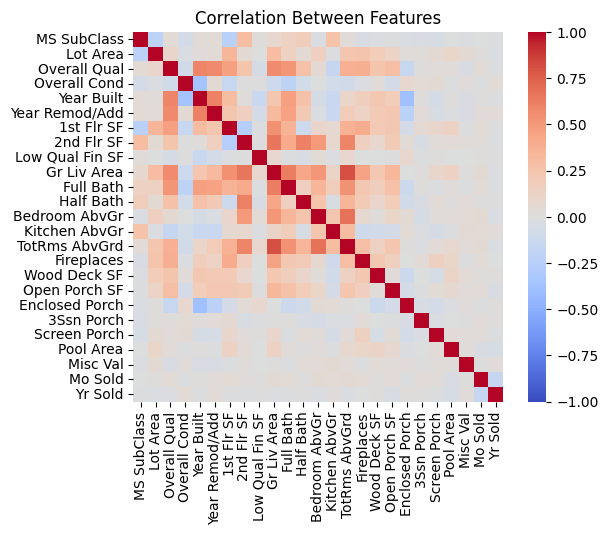

In [ ]:
# Display the correlation matrix of only features
sns.heatmap(
    corr_feat,
    square=True,
    annot=False,
    fmt='d',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Correlation Between Features');

##### Correlation Ranking

In [ ]:
# Calculate a correlation matrix for the features
corr_feat2 = iso_df_clean.drop(columns=target_col).corr().round(2).unstack().abs()
corr_feat2.reset_index()

,level_0,level_1,0
0,MS SubClass,MS SubClass,1.00
1,MS SubClass,Lot Area,0.22
2,MS SubClass,Overall Qual,0.05
3,MS SubClass,Overall Cond,0.07
4,MS SubClass,Year Built,0.04
...,...,...,...
620,Yr Sold,Screen Porch,0.01
621,Yr Sold,Pool Area,0.05
622,Yr Sold,Misc Val,0.03
623,Yr Sold,Mo Sold,0.16


In [ ]:
# Create a data series with features ranked by correlation
corr_feat2 = corr_feat2[corr_feat2 < 1]
corr_feat2.reset_index()

,level_0,level_1,0
0,MS SubClass,Lot Area,0.22
1,MS SubClass,Overall Qual,0.05
2,MS SubClass,Overall Cond,0.07
3,MS SubClass,Year Built,0.04
4,MS SubClass,Year Remod/Add,0.04
...,...,...,...
595,Yr Sold,3Ssn Porch,0.01
596,Yr Sold,Screen Porch,0.01
597,Yr Sold,Pool Area,0.05
598,Yr Sold,Misc Val,0.03


In [ ]:
corr_feat2.sort_values(ascending = False)[::2].reset_index()


,level_0,level_1,0
0,TotRms AbvGrd,Gr Liv Area,0.81
1,Bedroom AbvGr,TotRms AbvGrd,0.68
2,Gr Liv Area,2nd Flr SF,0.66
3,Full Bath,Gr Liv Area,0.63
4,2nd Flr SF,Half Bath,0.61
...,...,...,...
295,Low Qual Fin SF,Lot Area,0.00
296,Fireplaces,Yr Sold,0.00
297,Half Bath,Yr Sold,0.00
298,Lot Area,Low Qual Fin SF,0.00


<Axes: >

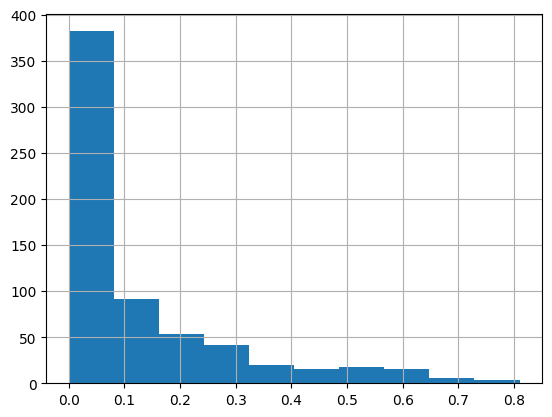

In [ ]:
corr_mat.hist()

What do we notice?

*   A few features are highly correlated with other features as well as the target



## Data Processing

## Data Visualization

## Communication of Results